In [24]:
divergences_1d <- function( stan_model, data_stan, log_post, y, nu = 1 )
{

  require(rstan)

  ## Posterior

  un_post <- Vectorize( function(theta)
  {
    exp( log_post(theta, y ) )
  }, "theta" )

  nc <- integrate(un_post, -Inf, Inf)$value

  posterior <- Vectorize( function(theta, m = F, sd2 = F )
  {
    if(m == T){
     return( theta*un_post(theta)/nc )
    }

    if(sd2 == T){
      return( theta^2*un_post(theta)/nc )
    }

    return(un_post(theta)/nc)

  }, "theta" )


  # KL for Gaussian VB

  kl_gaussian_target <- function(pars)
  {
    mu_gvb  <- pars[1]
    log_sd_gvb  <- pars[2] # taking log for unconstrained optimization

    # Integral prior

    prior_int <- Vectorize( function(theta){
                            log1p(theta^2/nu)*dnorm(theta,mu_gvb, exp(log_sd_gvb) )},
                            "theta")
    int_contr <-  tryCatch( integrate( prior_int, -Inf, Inf )$value,
                            error = function(e) integrate( prior_int, -8, 8 )$value)

    return( -log_sd_gvb +   (nu + 1)/2*int_contr
            - mu_gvb*sum(y) + length(y)*exp( mu_gvb + exp( 2*log_sd_gvb )/2 )
          )
  }


  # Symmetric approximation

  sym_app <- Vectorize( function(theta,...)
  {
    dnorm(theta,...)
  }, "theta")

  # Skew-symmetric approximation

  w <- function(theta, xi)
  {
    if( is.infinite(log_post(Inf, y)) &  is.infinite(log_post(2*xi - theta, y ) ))
    {
      return(0.5)
    }
    max( 1/(1 + exp( - log_post(theta, y) + log_post(2*xi - theta, y ) ) ), 0)
  }

  skew_app <-  Vectorize( function(theta,m_appr, sd_appr)
  {
    2*dnorm(theta,m_appr, sd_appr)*w(theta,m_appr)
  }, "theta")

  # divergences:
  # function that takes mean and sd and compute TV, KL and rev-KL

  divergences <- function(m_app, sd_app )
  {
    # symmetric divergences
    fun_tv_sym <- Vectorize( function(theta)
    {
      0.5*abs( posterior(theta) - sym_app(theta, m_app, sd_app)  )
    },
    "theta")

    fun_kl_sym <- Vectorize( function(theta)
    {
      if( sym_app(theta, m_app, sd_app) == 0 )
      {
        return(0)
      }
      ( -(theta - m_app)^2/(2*sd_app^2) - 0.5*log( 2*pi*sd_app^2)
         - log_post(theta,y) + log(nc)  ) *sym_app(theta, m_app, sd_app)
    },
    "theta")

    fun_rkl_sym <- Vectorize( function(theta)
    {
      if( posterior(theta) == 0 )
      {
        return(0)
      }
      ( log_post(theta,y) - log(nc) + (theta - m_app)^2/(2*sd_app^2) + 0.5*log( 2*pi*sd_app^2)   )*posterior(theta)
    },
    "theta")
    tv_sym <- max( integrate( fun_tv_sym, -Inf, Inf )$value, 1e-14)
    kl_sym <- max( integrate( fun_kl_sym, -Inf, Inf )$value, 1e-14)
    rkl_sym <- max( integrate( fun_rkl_sym, -Inf, Inf )$value, 1e-14)

    # skew-symmetric divergences
    fun_tv_skew <- Vectorize( function(theta)
    {
      0.5*abs( posterior(theta) - skew_app(theta, m_app, sd_app)  )
    },
    "theta")

    fun_kl_skew <- Vectorize( function(theta)
    {
      if( skew_app(theta, m_app, sd_app) == 0 )
      {
        return(0)
      }
      ( -(theta - m_app)^2/(2*sd_app^2) - 0.5*log( 2*pi*sd_app^2) + log(2)
        +  log(w(theta,m_app))
        - log_post(theta,y) + log(nc)  ) *skew_app(theta, m_app, sd_app)
    },
    "theta")

    fun_rkl_skew <- Vectorize( function(theta)
    {
      if( posterior(theta) == 0 )
      {
        return(0)
      }

      if(  is.finite( out <- ( log_post(theta,y) - log(nc) +
                               (theta - m_app)^2/(2*sd_app^2) + 0.5*log( 2*pi*sd_app^2) - log(2)
                               - log(w(theta,m_app))
          )*posterior(theta) ) )
      {
        return(out)
      }
      else{ 0 }
    },
    "theta")


    tv_skew <- max( integrate( fun_tv_skew, -Inf, Inf  )$value, 1e-14)
    kl_skew <- max(integrate( fun_kl_skew,  -Inf, Inf  )$value, 1e-14)
    rkl_skew <- max(integrate( fun_rkl_skew,  -Inf, Inf  )$value, 1e-14)

    return( list( tv_sym = tv_sym, kl_sym = kl_sym, rkl_sym = rkl_sym,
                  tv_skew = tv_skew, kl_skew = kl_skew, rkl_skew = rkl_skew  ) )

  }



  ## Gaussian approximations
  # Laplace
    fit_lap <- rstan::optimizing(
    stan_model,
    data = data_stan,
    hessian = TRUE
  )

  m_lap <- fit_lap$theta_tilde
  sd_lap <- sqrt(-1/fit_lap$hessian)

  # Divergences Laplace
  div_lap <- divergences(m_lap, sd_lap)
  tv_lap <- div_lap$tv_sym
  kl_lap <- div_lap$kl_sym
  rkl_lap <- div_lap$rkl_sym
  tv_skewlap <- div_lap$tv_skew
  kl_skewlap <- div_lap$kl_skew
  rkl_skewlap <- div_lap$rkl_skew


  # GVB
  pars_gvb  <- optim( c(0,0), kl_gaussian_target, method = "BFGS")
  m_gvb <- pars_gvb$par[1]
  sd_gvb  <- exp(pars_gvb$par[2])

  # Divergences GVB
  div_gvb <- divergences(m_gvb, sd_gvb)
  tv_gvb <- div_gvb$tv_sym
  kl_gvb <- div_gvb$kl_sym
  rkl_gvb <- div_gvb$rkl_sym
  tv_skewgvb <- div_gvb$tv_skew
  kl_skewgvb <- div_gvb$kl_skew
  rkl_skewgvb <- div_gvb$rkl_skew


  #EP
  m_ep <- integrate(posterior, - Inf, Inf, m = T )$value
  sd_ep <- sqrt(integrate(posterior, - Inf, Inf, sd2 = T )$value - m_ep^2)

  # Divergences EP
  div_ep <- divergences(m_ep, sd_ep)
  tv_ep <- div_ep$tv_sym
  kl_ep <- div_ep$kl_sym
  rkl_ep <- div_ep$rkl_sym
  tv_skewep <- div_ep$tv_skew
  kl_skewep <- div_ep$kl_skew
  rkl_skewep <- div_ep$rkl_skew

  return( list(tv_lap = tv_lap, kl_lap = kl_lap, rkl_lap = rkl_lap,
               tv_skewlap = tv_skewlap, kl_skewlap = kl_skewlap, rkl_skewlap = rkl_skewlap,
               tv_gvb = tv_gvb, kl_gvb = kl_gvb, rkl_gvb = rkl_gvb,
               tv_skewgvb = tv_skewgvb, kl_skewgvb = kl_skewgvb, rkl_skewgvb = rkl_skewgvb,
               tv_ep = tv_ep, kl_ep = kl_ep, rkl_ep = rkl_ep,
               tv_skewep = tv_skewep, kl_skewep = kl_skewep, rkl_skewep = rkl_skewep
                ) )

}

In [25]:
# Log-sum-exp
logSumExp <- function(values)
{
  m <- max(values)
  return(m + log( sum( exp(values - m) ) ))
}

# Skewing function joint distribution
w_joint <- function(sim, xi, log_post, ...)
{
  w1 <- log_post(sim,...)
  w2 <- log_post(2*xi -sim,...)
  pr <- 1/(1 + exp( w2 - w1 ))
  pr
}

# Sim skew for importance sampling
sim_skew <- function(sim, m, weights)
{
  bern <- rbinom(dim(sim)[1], 1, weights  )
  sim[bern == 0,] <- t( 2 * m - t(sim[bern == 0, ] ) )
  weights[bern == 0] <- 1 - weights[bern == 0]
  return( list( sim = sim, weights = weights, bern = bern  ) )
}

# Test subset: compute with mcmc a proxy of the kl-divergence
kl_up_to_const <- function(sims, weights, m,... )
{
  sim <- rbind( sims, t(- t(sims) + 2 * m ) )
  w <- c(weights, 1 - weights )
  out1 <- rep(NA, length(w))
  out1[w>0] <- log(2 * w[(w > 0) ]) * ( 2 * w[(w > 0) ])
  out1[w == 0] <- 0
  out2 <- ( (apply(sim, 1, function(k) log_post(k,...)) * ( 2 * w - 1)) )
  est <-  2*mean(out1 - out2 )
  sd.est <- sqrt( sum( (out1 - out2 - est )^2 )/length(weights) )
  return(list( est = est , sd.est = sd.est ))
}

# KL divergence, TV, bias etc
# x: a sample from the approximation
# y : a sample from the target density

compute_kl_tv <- function(x, y, smoothing = 6e-12, n_bins = 300, weights = NULL) {
  require(weights)
  # Check input
  if (!is.numeric(x) || !is.numeric(y)) {
    stop("Both input must be numeric vectors.")
  }
  if (length(x) < 2 || length(y) < 2) {
    stop("Both vector must have at least to elements.")
  }
  # Brakes of the sample space
  combined_range <- range(c(x, y))
  breaks <- seq(combined_range[1], combined_range[2], length.out = n_bins + 1)
  # Empirical densities (normalized histograms)
  if(is.null(weights))
  {
    x_density <- hist(x, breaks = breaks, plot = FALSE)
    y_density <- hist(y, breaks = breaks, plot = FALSE)
    bias <- abs(mean(x) - mean(y))/sd(y)
  }
  else{
    x_density <- wtd.hist(x, breaks = breaks, plot = FALSE, weight = weights)
    y_density <- wtd.hist(y, breaks = breaks, plot = FALSE)
    bias <- abs(2*mean(x*weights)- mean(y))/sd(y)
  }
  # Normalied probabilities with smoothing
  p_x <- (x_density$counts + smoothing) / sum(x_density$counts + smoothing)
  p_y <- (y_density$counts + smoothing) / sum(y_density$counts + smoothing)
  #KL divergence
  kl_divergence <- sum(p_x * log(p_x / p_y))
  #Rev-KL divergence
  rev_kl_divergence <- sum(p_y * log(p_y / p_x))
  #TV distance
  tv_distance <- (1/2)*sum( abs( p_x - p_y ) )
  return(list(kl_divergence =kl_divergence, rev_kl_divergence = rev_kl_divergence,
              tv_distance = tv_distance, bias = bias  ) )
}

# Function computing the bias of an approximation
compute_bias <- function( x, y, weights = NULL)
{
  if(is.null(weights))
  {
    bias <- mean(abs( apply(x,2,mean) - apply(y,2,mean) ))
  }
  else{
    bias <- mean(abs( apply(x,2, function(k) sum( weights * k )/(length(k)/2) ) - apply(y,2,mean) ))
  }

  return(bias)
}

# Weights importance sample
# weights = weights skew-symmetric
weights_is <- function(sim, m, Cov, weights, log_post,...)
{
  d <- dim(sim)[2]
  log_nc <- - (d/2)*log(det(Cov))
  prec <- solve(Cov)
  log_p <- apply(sim, 1, function(k) log_post(k,...) )
  log_gaus <-  apply(sim, 1, function(k) - 0.5 * t(k - m)%*%prec%*%(k - m) )
  log_w <- log_p - log_gaus - log(2 * weights ) + log_nc
  max_log <- max(log_w)
  exp( log_w - max_log )
}
# Function to compute ESS from a vector of un-normalized weights
ess <- function(w_is) {
  sum_w <- sum(w_is)
  return((sum_w)^2 / sum(w_is^2) * 1 / length(w_is))
}


# Function multiple ESS
multiple_ess <- function(nsim, m, Cov,log_post, N = 10^4,...)
{
  ess_rep <- ess_is_s <-ess_is<- rep(NA, nsim)
  for(k in 1:nsim)
  {
    sim <- mvtnorm::rmvnorm(N, mean = m, sigma = Cov  )
    w_skew <- apply(sim, 1, function(r) w_joint(r, m, log_post))
    sim_s <- sim_skew(sim,m,w_skew)
    weights_sim_s <- sim_s$weights
    sim_s <- sim_s$sim

    # Weights is
    weights_is <- weights_is(sim,
                             m,
                             Cov,
                             rep(0.5,N),
                             log_post)
    weights_is_s <- weights_is(sim_s,
                               m,
                               Cov,
                               weights_sim_s,
                               log_post)
    ess_is_s[k] <- ess(weights_is_s)
    ess_is[k] <- ess(weights_is)
  }

  ess_rep <- 100*ess_is_s/ess_is - 100

  return(list(ess_rep= ess_rep,
              ess_is_s = N * ess_is_s,
              ess_is = N * ess_is ))
}

In [26]:
install.packages("rstan")
library(rstan)

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

Warning message in install.packages("rstan"):
“installation of package ‘rstan’ had non-zero exit status”


In [27]:
poisson_model_code_1d <- "
data {
  int<lower=0> N;          // Number of observations
  array[N] int<lower=0> y; // Response variable (modern syntax)
  real<lower=0> nu;        // Degrees of freedom for Student-t prior
}

parameters {
  real theta;              // Latent parameter / intercept
}

model {
  // Student-t prior on theta
  theta ~ student_t(nu, 0, 1);

  // Poisson likelihood
  y ~ poisson(exp(theta));
}
"

# Compile the model
poisson_model_stan_1d <- stan_model( model_code = poisson_model_code_1d)

In [28]:
# Log-posterior of the model
log_post <- function(theta, y, nu = 1 )
{
  # prior
  prior <- -(nu+1)/2*log1p(theta^2/nu)
  # likelihood
  lik <- sum(y)*theta - length(y)*exp(theta)
  return( prior + lik )
}

In [29]:
# Simulation study: 50 different sequences data simulations

# true parameter
theta_0 <- 0

# number of simulations
nsim <- 50

# sample size
N <- seq(15,150, by = 10)

# allocate matrices that will contain the results of the simulation
tv_lap <- kl_lap <- rkl_lap <-tv_gvb <-
  kl_gvb <- rkl_gvb <-tv_ep <- kl_ep <- rkl_ep <- matrix(NA,nrow = nsim, ncol = length(N) )
tv_skewlap <- kl_skewlap <- rkl_skewlap <-tv_skewgvb<-
  kl_skewgvb <- rkl_skewgvb <-tv_skewep <- kl_skewep <- rkl_skewep <-matrix(NA,nrow = nsim, ncol = length(N) )

In [30]:
# run the simulation
set.seed(123)
for(j in 1:nsim)
{
  for( i in 1:length(N) )
  {
    # simulate data
    y <- rpois(N[i], exp( theta_0 ) )
    data <- list( N = N[i] ,   y = y ,  nu = 1 )

    # compute divergence for all the approximations
    out <- divergences_1d(stan_model = poisson_model_stan_1d, data_stan = data,log_post = log_post, y = y, nu = 1)

    # extract divergence Laplace
    tv_lap[j,i] <- out$tv_lap
    kl_lap[j,i] <-  out$kl_lap
    rkl_lap[j,i] <- out$rkl_lap

    # extract divergence GVB
    tv_gvb[j,i] <- out$tv_gvb
    kl_gvb[j,i] <- out$kl_gvb
    rkl_gvb[j,i] <- out$rkl_gvb

    # extract divergence GEP
    tv_ep[j,i] <- out$tv_ep
    kl_ep[j,i] <- out$kl_ep
    rkl_ep[j,i] <- out$rkl_ep

    # extract divergence skew-Laplace
    tv_skewlap[j,i] <- out$tv_skewlap
    kl_skewlap[j,i] <-  out$kl_skewlap
    rkl_skewlap[j,i] <- out$rkl_skewlap

    # extract divergence skew-GVB
    tv_skewgvb[j,i] <- out$tv_skewgvb
    kl_skewgvb[j,i] <- out$kl_skewgvb
    rkl_skewgvb[j,i] <- out$rkl_skewgvb

    # extract divergence skew-GEP
    tv_skewep[j,i] <- out$tv_skewep
    kl_skewep[j,i] <- out$kl_skewep
    rkl_skewep[j,i] <- out$rkl_skewep

  }
  print(j)
}

[1] 1
[1] 2
[1] 3
[1] 4
[1] 5
[1] 6
[1] 7
[1] 8
[1] 9
[1] 10
[1] 11
[1] 12
[1] 13
[1] 14
[1] 15
[1] 16
[1] 17
[1] 18
[1] 19
[1] 20
[1] 21
[1] 22
[1] 23
[1] 24
[1] 25
[1] 26
[1] 27
[1] 28
[1] 29
[1] 30
[1] 31
[1] 32
[1] 33
[1] 34
[1] 35
[1] 36
[1] 37
[1] 38
[1] 39
[1] 40
[1] 41
[1] 42
[1] 43
[1] 44
[1] 45
[1] 46
[1] 47
[1] 48
[1] 49
[1] 50


In [31]:
save.image(file="Simulation1DEnvironment.RData")
load(file='Simulation1DEnvironment.RData')

In [32]:
# Laplace

# Slope Laplace TV
slope_tvlap <- apply( log(tv_lap), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
tvlap_mean <- round( mean(slope_tvlap), 2)
tvlap_sd <- round( sd( slope_tvlap)/sqrt( length( slope_tvlap ) ),2)

# Slope skew-Laplace TV
slope_tvslap <- apply( log(tv_skewlap), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
tvslap_mean <-round( mean(slope_tvslap),2)
tvslap_sd <- round( sd( slope_tvslap)/sqrt( length( slope_tvslap ) ),2)

# Slope Laplace rev-KL
slope_rkllap <- apply( log(rkl_lap), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
rkllap_mean <- round( mean(slope_rkllap),2)
rkllap_sd <- round(sd( slope_rkllap)/sqrt( length( slope_rkllap ) ),2)

# Slope skew-Laplace rev-KL
slope_rklslap <- apply( log(rkl_skewlap), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
rklslap_mean <- round(mean(slope_rklslap),2)
rklslap_sd <- round( sd( slope_rklslap)/sqrt( length( slope_rklslap ) ),2)

# Slope Laplace KL
slope_kllap <- apply( log(kl_lap), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
kllap_mean <- round(mean(slope_kllap),2)
kllap_sd <- round(sd( slope_kllap)/sqrt( length( slope_kllap ) ),2)

# Slope skew-Laplace KL
slope_klslap <- apply( log(kl_skewlap), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
klslap_mean <- round(mean(slope_klslap),2)
klslap_sd <- round(sd( slope_klslap)/sqrt( length( slope_klslap ) ),2)

# Final table Laplace and skew-Laplace
lap_table <- rbind(
c( "Laplace" , "TV" , tvlap_mean, tvlap_sd, tvslap_mean, tvslap_sd ),
c( " " , "KL" , kllap_mean, kllap_sd, klslap_mean, klslap_sd ),
c( " " , "rev-KL" , rkllap_mean, rkllap_sd, rklslap_mean, rklslap_sd ) )
colnames(lap_table) <- c( "Method", "Quantity", "Gaussian", "Sd Gaussian",
                          "Skew-symmetric", "Sd skew-symmetric")
lap_table

Method,Quantity,Gaussian,Sd Gaussian,Skew-symmetric,Sd skew-symmetric
Laplace,TV,-0.48,0.01,-1.04,0.02
,KL,-0.93,0.02,-1.8,0.08
,rev-KL,-0.97,0.02,-3.11,0.26


In [33]:
# Average across all simulations at each sample size

# Laplace TV
avg_sim_tvlap <- colMeans(tv_lap)
# Skew-Laplace TV
avg_sim_tvslap <- colMeans(tv_skewlap)

# Laplace rev-KL
avg_sim_rkllap <- colMeans(rkl_lap)

# Skew-Laplace rev-KL
avg_sim_rklslap <- colMeans(rkl_skewlap)

# Laplace KL
avg_sim_kllap <- colMeans(kl_lap)

# Skew-Laplace KL
avg_sim_klslap <- colMeans(kl_skewlap)

# % Improvement
lap_improv <- data.frame(
  rbind(
    round((1 - avg_sim_tvslap  / avg_sim_tvlap)  * 100, 2),
    round((1 - avg_sim_klslap  / avg_sim_kllap)  * 100, 2),
    round((1 - avg_sim_rklslap / avg_sim_rkllap) * 100, 2)
  )
)

# Add Method column and set names correctly
lap_improv <- cbind(Quantity = c("TV", "KL", "rev-KL"), lap_improv)
lap_improv <- cbind(Method = c("Laplace", "", ""), lap_improv)
colnames(lap_improv) <- c("Method", "Quantity", N)

lap_improv

Method,Quantity,15,25,35,45,55,65,75,85,95,105,115,125,135,145
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Laplace,TV,77.43,83.44,86.63,88.82,90.09,91.01,91.63,92.00,92.56,93.11,93.27,93.50,93.86,94.09
,KL,87.35,91.78,93.91,95.42,96.13,96.52,96.06,97.24,97.43,97.71,97.24,97.53,97.58,96.74
,rev-KL,82.20,89.73,92.79,94.55,95.62,96.38,96.87,97.05,97.47,97.75,98.03,98.26,98.32,98.45


In [34]:
# Gaussian expectation-propagation (GEP)

# Slope GEP TV
slope_tvep <- apply( log(tv_ep), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
tvep_mean <- round( mean(slope_tvep), 2)
tvep_sd <- round( sd( slope_tvep)/sqrt( length( slope_tvep ) ),2)

# Slope skew-GEP TV
slope_tvsep <- apply( log(tv_skewep), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
tvsep_mean <-round( mean(slope_tvsep),2)
tvsep_sd <- round( sd( slope_tvsep)/sqrt( length( slope_tvsep ) ),2)

# Slope GEP rev-KL
slope_rklep <- apply( log(rkl_ep), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
rklep_mean <- round( mean(slope_rklep),2)
rklep_sd <- round(sd( slope_rklep)/sqrt( length( slope_rklep ) ),2)

# Slope skew-GEP rev-KL
slope_rklsep <- apply( log(rkl_skewep), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
rklsep_mean <- round(mean(slope_rklsep),2)
rklsep_sd <- round( sd( slope_rklsep)/sqrt( length( slope_rklsep ) ),2)

# Slope GEP KL
slope_klep <- apply( log(kl_ep), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
klep_mean <- round(mean(slope_klep),2)
klep_sd <- round(sd( slope_klep)/sqrt( length( slope_klep ) ),2)

# Slope skew-GEP KL
slope_klsep <- apply( log(kl_skewep), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
klsep_mean <- round(mean(slope_klsep),2)
klsep_sd <- round(sd( slope_klsep)/sqrt( length( slope_klsep ) ),2)

# Final table GEP and skew-GEP
ep_table <- rbind(
  c( "GEP" , "TV" , tvep_mean, tvep_sd, tvsep_mean, tvsep_sd ),
  c( " " , "KL" , klep_mean, klep_sd, klsep_mean, klsep_sd ),
  c( " " , "rev-KL" , rklep_mean, rklep_sd, rklsep_mean, rklsep_sd ) )
colnames(ep_table) <- c( "Method", "Quantity", "Gaussian", "Sd Gaussian",
                         "Skew-symmetric", "Sd skew-symmetric")
ep_table

Method,Quantity,Gaussian,Sd Gaussian,Skew-symmetric,Sd skew-symmetric
GEP,TV,-0.48,0.01,-1.05,0.02
,KL,-0.95,0.02,-1.73,0.12
,rev-KL,-0.98,0.02,-3.18,0.29


In [35]:
# Average across all simulations at each sample size

# GEP TV
avg_sim_tvep <- colMeans(tv_ep)
# Skew-GEP TV
avg_sim_tvsep <- colMeans(tv_skewep)

# GEP rev-KL
avg_sim_rklep <- colMeans(rkl_ep)

# Skew-GEP rev-KL
avg_sim_rklsep <- colMeans(rkl_skewep)

# GEP KL
avg_sim_klep <- colMeans(kl_ep)

# Skew-GEP KL
avg_sim_klsep <- colMeans(kl_skewep)

# % Improvement
gep_improv <- data.frame(
  rbind(
    round((1 - avg_sim_tvsep  / avg_sim_tvep)  * 100, 2),
    round((1 - avg_sim_klsep  / avg_sim_klep)  * 100, 2),
    round((1 - avg_sim_rklsep / avg_sim_rklep) * 100, 2)
  )
)

# Add Method column and set names correctly
gep_improv <- cbind(Quantity = c("TV", "KL", "rev-KL"), gep_improv)
gep_improv <- cbind(Method = c("GEP", "", ""), gep_improv)
colnames(gep_improv) <- c("Method", "Quantity", N)

gep_improv

Method,Quantity,15,25,35,45,55,65,75,85,95,105,115,125,135,145
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GEP,TV,84.48,88.63,90.77,92.26,93.14,93.80,94.30,94.46,94.85,95.23,95.37,95.56,95.83,96.07
,KL,92.51,94.67,95.88,96.96,97.34,97.23,95.44,98.01,97.94,98.10,96.77,97.26,96.97,94.82
,rev-KL,88.77,93.46,95.42,96.32,97.09,97.47,97.84,98.03,98.26,98.46,98.73,98.78,98.74,98.87


In [36]:
# Gaussian VB (GVB)

# Slope GVB TV
slope_tvgvb <- apply( log(tv_gvb), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
tvgvb_mean <- round( mean(slope_tvgvb), 2)
tvgvb_sd <- round( sd( slope_tvgvb)/sqrt( length( slope_tvgvb ) ),2)

# Slope skew-GVB TV
slope_tvsgvb <- apply( log(tv_skewgvb), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
tvsgvb_mean <-round( mean(slope_tvsgvb),2)
tvsgvb_sd <- round( sd( slope_tvsgvb)/sqrt( length( slope_tvsgvb ) ),2)

# Slope GVB rev-KL
slope_rklgvb <- apply( log(rkl_gvb), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
rklgvb_mean <- round( mean(slope_rklgvb),2)
rklgvb_sd <- round(sd( slope_rklgvb)/sqrt( length( slope_rklgvb ) ),2)

# Slope skew-GVB rev-KL
slope_rklsgvb <- apply( log(rkl_skewgvb), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
rklsgvb_mean <- round(mean(slope_rklsgvb),2)
rklsgvb_sd <- round( sd( slope_rklsgvb)/sqrt( length( slope_rklsgvb ) ),2)

# Slope GVB KL
slope_klgvb <- apply( log(kl_gvb), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
klgvb_mean <- round(mean(slope_klgvb),2)
klgvb_sd <- round(sd( slope_klgvb)/sqrt( length( slope_klgvb ) ),2)

# Slope skew-GVB KL
slope_klsgvb <- apply( log(kl_skewgvb), 1, function(k) coef( lm(k ~ log(N)  ) )[2]  )
klsgvb_mean <- round(mean(slope_klsgvb),2)
klsgvb_sd <- round(sd( slope_klsgvb)/sqrt( length( slope_klsgvb ) ),2)

# Final table GVB and skew-GVB
gvb_table <- rbind(
  c( "GVB" , "TV" , tvgvb_mean, tvgvb_sd, tvsgvb_mean, tvsgvb_sd ),
  c( " " , "KL" , klgvb_mean, klgvb_sd, klsgvb_mean, klsgvb_sd ),
  c( " " , "rev-KL" , rklgvb_mean, rklgvb_sd, rklsgvb_mean, rklsgvb_sd ) )

colnames(gvb_table) <- c( "Method", "Quantity", "Gaussian", "Sd Gaussian",
                          "Skew-symmetric", "Sd skew-symmetric")
gvb_table

Method,Quantity,Gaussian,Sd Gaussian,Skew-symmetric,Sd skew-symmetric
GVB,TV,-0.47,0.01,-0.99,0.02
,KL,-0.93,0.02,-1.76,0.11
,rev-KL,-0.99,0.02,-3.47,0.26


In [37]:
# Average across all simulations at each sample size

# GVB TV
avg_sim_tvgvb <- colMeans(tv_gvb)
# Skew-GVB TV
avg_sim_tvsgvb <- colMeans(tv_skewgvb)

# GVB rev-KL
avg_sim_rklgvb <- colMeans(rkl_gvb)

# Skew-GVB rev-KL
avg_sim_rklsgvb <- colMeans(rkl_skewgvb)

# GVB KL
avg_sim_klgvb <- colMeans(kl_gvb)

# Skew-GVB KL
avg_sim_klsgvb <- colMeans(kl_skewgvb)

# % Improvement
gvb_improv <- data.frame(
  rbind(
    round((1 - avg_sim_tvsgvb / avg_sim_tvgvb)  * 100, 2),
    round((1 - avg_sim_klsgvb / avg_sim_klgvb)  * 100, 2),
    round((1 - avg_sim_rklsgvb/ avg_sim_rklgvb) * 100, 2)
  )
)

# Add Method column and set names correctly
gvb_improv <- cbind(Quantity = c("TV", "KL", "rev-KL"), gvb_improv)
gvb_improv <- cbind(Method = c("GVB", "", ""), gvb_improv)
colnames(gvb_improv) <- c("Method", "Quantity", N)

gvb_improv

Method,Quantity,15,25,35,45,55,65,75,85,95,105,115,125,135,145
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
GVB,TV,86.72,88.84,90.32,91.20,92.00,92.57,93.14,95.25,93.82,96.75,96.32,94.94,94.70,94.82
,KL,88.21,92.03,94.00,95.49,96.16,96.21,94.56,97.52,97.30,97.88,96.44,96.76,96.51,94.35
,rev-KL,83.34,90.47,93.32,94.67,95.85,96.41,96.94,97.54,97.59,98.22,98.44,98.34,98.27,98.42


In [38]:
# Final table combining all the three methods
final_table <- rbind(lap_table, ep_table, gvb_table)
final_table

Method,Quantity,Gaussian,Sd Gaussian,Skew-symmetric,Sd skew-symmetric
Laplace,TV,-0.48,0.01,-1.04,0.02
,KL,-0.93,0.02,-1.8,0.08
,rev-KL,-0.97,0.02,-3.11,0.26
GEP,TV,-0.48,0.01,-1.05,0.02
,KL,-0.95,0.02,-1.73,0.12
,rev-KL,-0.98,0.02,-3.18,0.29
GVB,TV,-0.47,0.01,-0.99,0.02
,KL,-0.93,0.02,-1.76,0.11
,rev-KL,-0.99,0.02,-3.47,0.26


In [39]:
improv_table <- rbind(lap_improv, gep_improv, gvb_improv)
improv_table

Method,Quantity,15,25,35,45,55,65,75,85,95,105,115,125,135,145
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Laplace,TV,77.43,83.44,86.63,88.82,90.09,91.01,91.63,92.00,92.56,93.11,93.27,93.50,93.86,94.09
,KL,87.35,91.78,93.91,95.42,96.13,96.52,96.06,97.24,97.43,97.71,97.24,97.53,97.58,96.74
,rev-KL,82.20,89.73,92.79,94.55,95.62,96.38,96.87,97.05,97.47,97.75,98.03,98.26,98.32,98.45
GEP,TV,84.48,88.63,90.77,92.26,93.14,93.80,94.30,94.46,94.85,95.23,95.37,95.56,95.83,96.07
,KL,92.51,94.67,95.88,96.96,97.34,97.23,95.44,98.01,97.94,98.10,96.77,97.26,96.97,94.82
,rev-KL,88.77,93.46,95.42,96.32,97.09,97.47,97.84,98.03,98.26,98.46,98.73,98.78,98.74,98.87
GVB,TV,86.72,88.84,90.32,91.20,92.00,92.57,93.14,95.25,93.82,96.75,96.32,94.94,94.70,94.82
,KL,88.21,92.03,94.00,95.49,96.16,96.21,94.56,97.52,97.30,97.88,96.44,96.76,96.51,94.35
,rev-KL,83.34,90.47,93.32,94.67,95.85,96.41,96.94,97.54,97.59,98.22,98.44,98.34,98.27,98.42


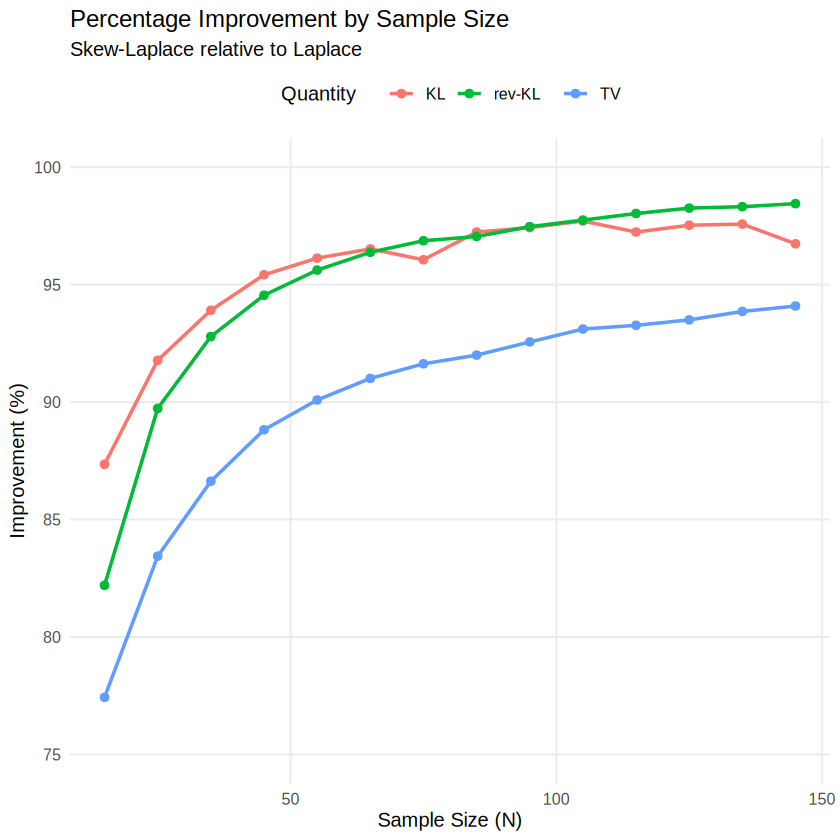

In [40]:
library(ggplot2)
library(tidyr)

plot_data_long <- pivot_longer(
  lap_improv[, !(colnames(lap_improv) %in% c("Method"))],
  cols = -Quantity,
  names_to = "N",
  values_to = "Improvement"
)

plot_data_long$N <- as.numeric(as.character(plot_data_long$N))
plot_data_long$Improvement <- as.numeric(as.character(plot_data_long$Improvement))


lap_p <- ggplot(plot_data_long, aes(x = N, y = Improvement, color = Quantity, group = Quantity)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  ylim(75, 100) +
  labs(
    title = "Percentage Improvement by Sample Size",
    subtitle = "Skew-Laplace relative to Laplace",
    x = "Sample Size (N)",
    y = "Improvement (%)",
    color = "Quantity"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    legend.position = "top",
    panel.grid.minor = element_blank()
  )

ggsave("lap_improvement_plot.pdf", plot = lap_p, width = 7, height = 5)
lap_p

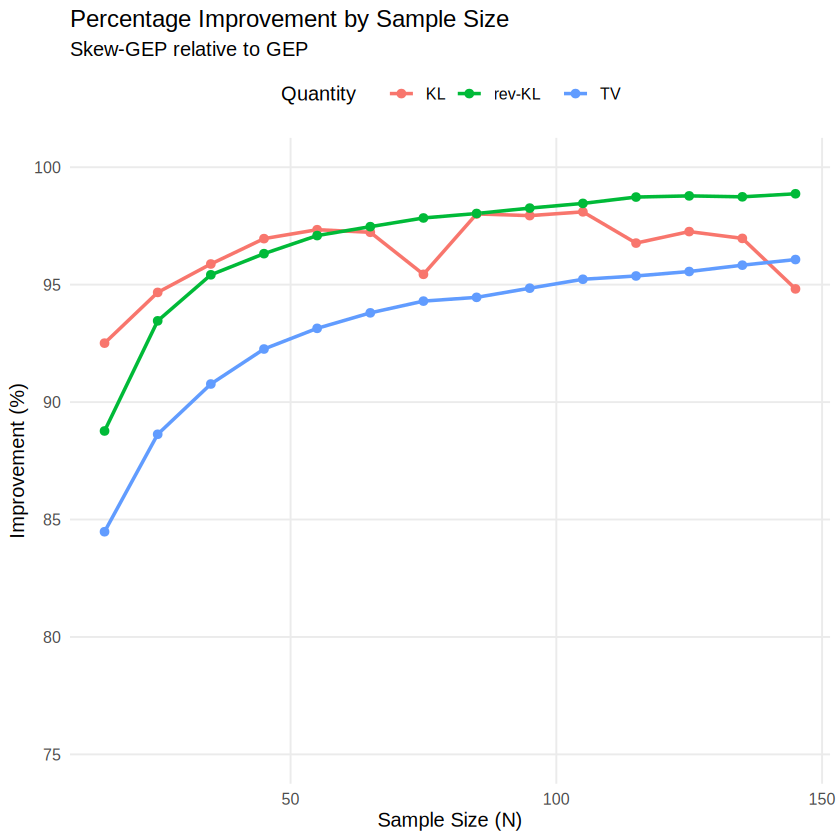

In [41]:
plot_data_long <- pivot_longer(
  gep_improv[, !(colnames(gep_improv) %in% c("Method"))],
  cols = -Quantity,
  names_to = "N",
  values_to = "Improvement"
)

plot_data_long$N <- as.numeric(as.character(plot_data_long$N))
plot_data_long$Improvement <- as.numeric(as.character(plot_data_long$Improvement))


gep_p <- ggplot(plot_data_long, aes(x = N, y = Improvement, color = Quantity, group = Quantity)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  ylim(75, 100) +
  labs(
    title = "Percentage Improvement by Sample Size",
    subtitle = "Skew-GEP relative to GEP",
    x = "Sample Size (N)",
    y = "Improvement (%)",
    color = "Quantity"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    legend.position = "top",
    panel.grid.minor = element_blank()
  )

ggsave("gep_improvement_plot.pdf", plot = gep_p, width = 7, height = 5)
gep_p

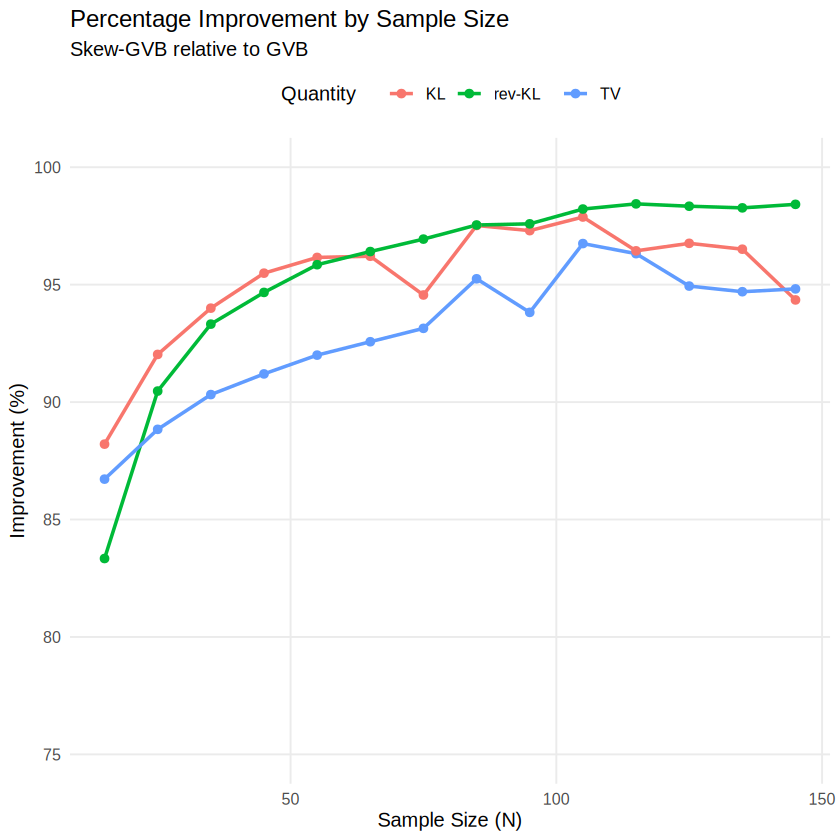

In [42]:
plot_data_long <- pivot_longer(
  gvb_improv[, !(colnames(gvb_improv) %in% c("Method"))],
  cols = -Quantity,
  names_to = "N",
  values_to = "Improvement"
)

plot_data_long$N <- as.numeric(as.character(plot_data_long$N))
plot_data_long$Improvement <- as.numeric(as.character(plot_data_long$Improvement))


gvb_p <- ggplot(plot_data_long, aes(x = N, y = Improvement, color = Quantity, group = Quantity)) +
  geom_line(linewidth = 1) +
  geom_point(size = 2) +
  ylim(75, 100) +
  labs(
    title = "Percentage Improvement by Sample Size",
    subtitle = "Skew-GVB relative to GVB",
    x = "Sample Size (N)",
    y = "Improvement (%)",
    color = "Quantity"
  ) +
  theme_minimal(base_size = 12) +
  theme(
    legend.position = "top",
    panel.grid.minor = element_blank()
  )

ggsave("gvb_improvement_plot.pdf", plot = gvb_p, width = 7, height = 5)
gvb_p